<a href="https://colab.research.google.com/github/hershiaytoda/walmart-hurricane-project/blob/main/walmart_hurricane_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics — DS2002 Midterm

**Team data-cane:** Megha (cleaning, Q1), Hershi (weather API + join, Q3), Angelia (Q2, Q4, Q5)

Weather source: **Open-Meteo Historical Weather API**, base URL `https://archive-api.open-meteo.com/v1/archive`

Reflection answers are in `README.md`.

## Setup

In [2]:
import os
# cloning repo since data isn't there yet
if not os.path.exists("data") and not os.path.exists("../data"):
    !git clone -q https://github.com/hershiaytoda/walmart-hurricane-project.git
    %cd walmart-hurricane-project

/content/walmart-hurricane-project


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import requests
import time
from pathlib import Path

# works whether the notebook runs from the repo root or from notebooks/
DATA = Path("data") if Path("data").exists() else Path("../data")

# analysis windows used for every question
BASELINE = ("2024-09-01", "2024-09-15")   # 15 normal days before any rise
SURGE    = ("2024-09-19", "2024-09-25")   # the 7 days before landfall
LANDFALL = pd.Timestamp("2024-09-26")     # Hurricane Helene landfall

## Load the data

All files are loaded as text first (`dtype=str`) so pandas doesnt guess types wrong, then we fix types during cleaning.

In [4]:
raw = pd.read_csv(DATA / "walmart_transactions.csv", dtype=str)
stores_raw = pd.read_csv(DATA / "store_locations.csv", dtype=str)
catalog = pd.read_csv(DATA / "product_catalog.csv", dtype=str)
dcs = pd.read_csv(DATA / "distribution_centers.csv", dtype=str)

conn = sqlite3.connect(DATA / "inventory_and_sales.db")
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))
dss = pd.read_sql("SELECT * FROM daily_sales_summary", conn)
inv = pd.read_sql("SELECT * FROM inventory_levels", conn)

for name, df in [("transactions", raw), ("stores", stores_raw), ("catalog", catalog),
                 ("distribution centers", dcs), ("daily_sales_summary", dss), ("inventory_levels", inv)]:
    print(f"{name}: {df.shape}")

                  name
0  daily_sales_summary
1     inventory_levels
transactions: (25562, 8)
stores: (14, 8)
catalog: (45, 7)
distribution centers: (5, 8)
daily_sales_summary: (3600, 5)
inventory_levels: (4320, 6)


In [5]:
raw.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


In [6]:
# quick profile of the problems
print("exact duplicate rows:", raw.duplicated().sum())
print("missing values per column:")
print(raw.isna().sum())
print("\nprices with a $:", raw["unit_price"].str.contains(r"\$", na=False).sum())
print("negative quantities:", (pd.to_numeric(raw["quantity"], errors="coerce") < 0).sum())
print("\nstore_id spellings:", raw["store_id"].nunique(), "->", sorted(raw["store_id"].unique())[:12])
print("\ncategory spellings:", raw["category"].nunique())
print("timestamp examples:", raw["timestamp"].dropna().sample(6, random_state=1).tolist())

exact duplicate rows: 30
missing values per column:
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64

prices with a $: 3029
negative quantities: 130

store_id spellings: 60 -> [' FL-078', ' FL-105', ' FL-156', ' FL-239', ' FL-287', ' FL-302', ' FL-330', ' FL-412', ' FL-445', ' FL-501', ' FL-619', ' FL-710']

category spellings: 37
timestamp examples: ['2024-09-25 08:15:16', '2024-09-20 12:03:47', '2024-09-26 16:39:04', '2024-09-16T15:35:18', '09/25/2024 20:08', '2024-09-11 10:31:44']


## Cleaning pipeline (Megha)

In [7]:
def clean_store_id(s):
    # fl-412, FL_412, FL412 -> FL-412
    return (s.astype(str).str.strip().str.upper()
             .str.replace("_", "-", regex=False)
             .str.replace(r"^FL(\d+)$", r"FL-\1", regex=True))

CATEGORY_MAP = {
    "emergency supplies": "emergency", "groceries": "grocery",
    "games & entertainment": "entertainment", "household essentials": "household",
    "baby products": "baby", "breakfast foods": "breakfast",
    "alcoholic beverages": "alcohol", "health & wellness": "health",
}

def clean_category(s):
    s = s.str.strip().str.lower().replace(CATEGORY_MAP)
    return s.str.title()

def clean_transactions(raw):
    log = []
    tx = raw.drop_duplicates().copy()
    log.append(("Exact duplicate rows", "Dropped", len(raw) - len(tx)))

    tx["timestamp"] = pd.to_datetime(tx["timestamp"].str.strip(), format="mixed", errors="coerce")
    n = tx["timestamp"].isna().sum()
    tx = tx.dropna(subset=["timestamp"]).copy()
    log.append(("Missing / unparseable timestamp", "Parsed with format='mixed', dropped rows with no timestamp", n))

    n = tx["unit_price"].str.contains(r"\$", na=False).sum()
    tx["unit_price"] = pd.to_numeric(tx["unit_price"].str.replace(r"[$,\s]", "", regex=True), errors="coerce")
    tx["quantity"] = pd.to_numeric(tx["quantity"], errors="coerce")
    log.append(("unit_price stored as text with $", "Removed $ and converted to number", n))

    n = (tx["quantity"] <= 0).sum()
    tx = tx[tx["quantity"] > 0].copy()
    log.append(("Negative quantity", "Dropped (returns / entry errors, sales only)", n))

    n = (clean_store_id(tx["store_id"]) != tx["store_id"]).sum()
    tx["store_id"] = clean_store_id(tx["store_id"])
    log.append(("Inconsistent store_id format", "Standardized to FL-###", n))

    n = (clean_category(tx["category"]) != tx["category"]).sum()
    tx["category"] = clean_category(tx["category"])
    log.append(("Category spelled 37 different ways", "Lowercased, merged synonyms -> 10 categories", n))

    tx["sku"] = tx["sku"].str.strip()
    tx["revenue"] = tx["quantity"] * tx["unit_price"]
    tx["date"] = tx["timestamp"].dt.normalize()
    return tx, log

tx, log = clean_transactions(raw)
print(f"{len(raw):,} raw rows -> {len(tx):,} clean rows")
print("categories now:", sorted(tx["category"].unique()))

25,562 raw rows -> 24,521 clean rows
categories now: ['Alcohol', 'Baby', 'Breakfast', 'Electronics', 'Emergency', 'Entertainment', 'Grocery', 'Health', 'Household', 'Snacks']


In [8]:
# TODO (Megha): decision log
decision_log = pd.DataFrame(log, columns=["Data issue", "Decision", "Rows affected"])
decision_log

,Data issue,Decision,Rows affected
0,Exact duplicate rows,Dropped,30
1,Missing / unparseable timestamp,"Parsed with format='mixed', dropped rows with ...",884
2,unit_price stored as text with $,Removed $ and converted to number,2915
3,Negative quantity,"Dropped (returns / entry errors, sales only)",127
4,Inconsistent store_id format,Standardized to FL-###,4174
5,Category spelled 37 different ways,"Lowercased, merged synonyms -> 10 categories",18009


## Weather API + join (Hershi)


In [24]:
import pandas as pd, numpy as np, requests, time
import matplotlib.pyplot as plt, seaborn as sns

tx = pd.read_csv("data/walmart_transactions.csv", dtype=str).drop_duplicates().copy()
tx["timestamp"] = pd.to_datetime(tx["timestamp"].str.strip(), format="mixed", errors="coerce")
tx = tx.dropna(subset=["timestamp"]).copy()
tx["quantity"] = pd.to_numeric(tx["quantity"], errors="coerce")
tx["unit_price"] = pd.to_numeric(tx["unit_price"].str.replace(r"[$,\s]", "", regex=True), errors="coerce")
tx = tx[tx["quantity"] > 0].copy()
tx["revenue"] = tx["quantity"] * tx["unit_price"]
tx["date"] = tx["timestamp"].dt.normalize()
tx["store_id"] = (tx["store_id"].str.strip().str.upper()
                  .str.replace("_", "-", regex=False)
                  .str.replace(r"^FL(\d+)$", r"FL-\1", regex=True))
tx["category"] = tx["category"].str.strip().str.title()

CAT_MAP = {
    "Emergency Supplies": "Emergency",
    "Groceries": "Grocery",
    "Games & Entertainment": "Entertainment",
    "Household Essentials": "Household",
    "Baby Products": "Baby",
    "Breakfast Foods": "Breakfast",
    "Alcoholic Beverages": "Alcohol",
    "Health & Wellness": "Health",
}
before = tx["category"].nunique()
tx["category"] = tx["category"].replace(CAT_MAP)
assert tx["category"].nunique() == 10
print(f"{before} category labels -> {tx['category'].nunique()}")
print(tx["category"].value_counts())

orlando = tx[tx["store_id"] == "FL-239"].copy()
print("Orlando rows:", len(orlando))

18 category labels -> 10
category
Emergency        6909
Grocery          3188
Entertainment    2435
Electronics      2419
Household        2240
Baby             2014
Breakfast        1975
Alcohol          1220
Health           1186
Snacks            935
Name: count, dtype: int64
Orlando rows: 2010


In [25]:
# TODO (Hershi): daily_weather() function with retries
BASE = "https://archive-api.open-meteo.com/v1/archive"
RETRY_STATUSES = {429, 500, 502, 503, 504}

def _get_json(params, tries=3):
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=15)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries: raise
            time.sleep(2 ** attempt); continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries: r.raise_for_status()
            time.sleep(2 ** attempt); continue
        r.raise_for_status()
        return r.json()

def daily_weather(start, end, lat, lon, tz="America/New_York"):
    """Daily precip + max wind, plus daily mean sea-level pressure from hourly data.
    Timezone is set so API dates are local days, matching local-time POS timestamps."""
    base = {"latitude": lat, "longitude": lon, "start_date": start,
            "end_date": end, "timezone": tz}
    d = _get_json({**base, "daily": "precipitation_sum,windspeed_10m_max"})
    assert d["timezone"] == tz, d["timezone"]   # proves API dates are America/New_York local days
    h = _get_json({**base, "hourly": "pressure_msl"})

    daily = pd.DataFrame(d["daily"]).rename(columns={"time": "date"})
    daily["date"] = pd.to_datetime(daily["date"])

    hourly = pd.DataFrame(h["hourly"])
    hourly["date"] = pd.to_datetime(hourly["time"]).dt.normalize()
    pressure = (hourly.groupby("date")["pressure_msl"].mean()
                .rename("pressure_mean_hpa").reset_index())

    out = daily.merge(pressure, on="date", how="left", validate="one_to_one")
    out["pressure_change_hpa"] = out["pressure_mean_hpa"].diff()
    out["source"] = "open-meteo (live API)"
    return out


In [26]:
# TODO (Hershi): call the API, show weather.head()

stores = pd.read_csv("data/store_locations.csv", dtype=str)
stores["store_id"] = (stores["store_id"].str.strip().str.upper()
                      .str.replace("_", "-", regex=False)
                      .str.replace(r"^FL(\d+)$", r"FL-\1", regex=True))
store = stores[stores["store_id"] == "FL-239"].iloc[0]

weather = daily_weather("2024-09-01", "2024-09-30",
                        lat=float(store["latitude"]), lon=float(store["longitude"]))

display(weather.head())
assert len(weather) == 30 and weather["date"].is_unique
print("Nulls per column:\n", weather.isna().sum())
print("Source:", weather["source"].iloc[0], "| base URL:", BASE)


,date,precipitation_sum,windspeed_10m_max,pressure_mean_hpa,pressure_change_hpa,source
0,2024-09-01,6.4,18.7,1014.070833,NaN,open-meteo (live API)
1,2024-09-02,22.0,12.7,1014.095833,0.025000,open-meteo (live API)
2,2024-09-03,32.7,20.6,1015.675000,1.579167,open-meteo (live API)
3,2024-09-04,21.2,12.6,1017.737500,2.062500,open-meteo (live API)
4,2024-09-05,20.8,15.2,1017.220833,-0.516667,open-meteo (live API)


Nulls per column:
 date                   0
precipitation_sum      0
windspeed_10m_max      0
pressure_mean_hpa      0
pressure_change_hpa    1
source                 0
dtype: int64
Source: open-meteo (live API) | base URL: https://archive-api.open-meteo.com/v1/archive


In [27]:
# TODO (Hershi): join daily sales to weather, check row counts

daily_sales = (orlando.groupby("date")
               .agg(units=("quantity", "sum"),
                    revenue=("revenue", "sum"),
                    transactions=("transaction_id", "nunique"))
               .reset_index())

daily = daily_sales.merge(weather, on="date", how="left",
                          validate="one_to_one", indicator=True)

print("Daily sales rows before join:", len(daily_sales))
print("Rows after join:", len(daily))
print(daily["_merge"].value_counts())
assert len(daily) == len(daily_sales)
assert (daily["_merge"] == "both").all()
daily = daily.drop(columns="_merge").set_index("date")
print("Days in correlation (n):", len(daily))

Daily sales rows before join: 30
Rows after join: 30
_merge
both          30
left_only      0
right_only     0
Name: count, dtype: int64
Days in correlation (n): 30


## Q1 — Demand surge (Megha)

Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.

In [ ]:
# TODO (Megha): % increase by category, baseline vs surge

In [ ]:
# TODO (Megha): line chart, daily trend for the top 5 categories

**Q1 answer:** TODO (Megha)

## Q2 — The Pop-Tarts Effect (Angelia)

First the sku mapping, then the before/after comparison.

SKU consolidation- Some products are listed under several sku codes and many product name spellings. The sku is more stable as it always means the same product. We map sku to the canonical product. Built by hand from `tx[["sku","product_name"]].drop_duplicates()`.



In [ ]:
CANON = {
    "PT-12": "Pop-Tarts Strawberry", "SKU#459812": "Pop-Tarts Strawberry",
    "POPTART-STRAW": "Pop-Tarts Strawberry", "PT_STRAWBERRY": "Pop-Tarts Strawberry",
    "WTR-24": "Bottled Water 24-Pack", "WATER24PK": "Bottled Water 24-Pack", "WTR_24PK": "Bottled Water 24-Pack",
    "BATT-100": "AA Batteries 4-Pack", "BAT-AA4": "AA Batteries 4-Pack", "BATT_AA_4PK": "AA Batteries 4-Pack",
    "FLASH-01": "LED Flashlight", "LED-FLASH": "LED Flashlight",
    "CANDLE-EMRG": "Emergency Candles", "CNDL-EM": "Emergency Candles",
    "TARP-HD": "Heavy Duty Tarp", "HDTARP-01": "Heavy Duty Tarp",
    "BEER-24": "Light Beer 24-Pack", "LTBEER24": "Light Beer 24-Pack",
    "BG-MONO": "Monopoly Board Game", "MONOPOLY-01": "Monopoly Board Game", "GAME-MONO": "Monopoly Board Game",
    "CARDS-01": "Playing Cards", "PLAYCARD-STD": "Playing Cards",
    "STREAM-01": "Roku Streaming Stick", "ROKU-STD": "Roku Streaming Stick",
    "CHRG-PORT": "Portable Phone Charger", "PORTCHARGER": "Portable Phone Charger",
    "SOUP-CAN": "Canned Soup", "CNSOUP-01": "Canned Soup",
    "PB-16": "Peanut Butter 16oz", "PNUTBTR-16": "Peanut Butter 16oz",
    "BREAD-WH": "White Bread", "WHITEBREAD": "White Bread",
    "CHIPS-VP": "Chips Variety Pack", "CHIPVARIETY": "Chips Variety Pack",
    "TP-12": "Toilet Paper 12-Roll", "TOILETPAPER12": "Toilet Paper 12-Roll",
    "PTOWEL-6": "Paper Towels 6-Roll", "PAPERTOWEL6": "Paper Towels 6-Roll",
    "FAID-01": "First Aid Kit", "FIRSTAID-KIT": "First Aid Kit",
    "BFORM-01": "Baby Formula", "BABYFORMULA": "Baby Formula",
    "DIAP-S3": "Diapers Size 3", "DIAPERS-3": "Diapers Size 3",
}
tx["canonical_product"] = tx["sku"].map(CANON)
print("unmapped skus:", list(tx.loc[tx["canonical_product"].isna(), "sku"].unique()))

unmapped skus: []
unmapped skus: []


In [ ]:
pt_raw = tx[tx["canonical_product"] == "Pop-Tarts Strawberry"]
print(pt_raw.groupby("sku")["product_name"].unique())

print("\nsku codes:", tx["sku"].nunique(), "| product_name spellings:", tx["product_name"].nunique(),
      "| canonical products:", tx["canonical_product"].nunique())

# mapping only relabels rows, it shouldnt change total units
assert tx["quantity"].sum() == tx.groupby("canonical_product")["quantity"].sum().sum()
print("total units unchanged:", int(tx["quantity"].sum()))

sku
POPTART-STRAW    [Strawberry Pop-Tart, pop-tarts strawberry, PO...
PT-12            [Pop Tarts - Strawberry, Strawberry Pop-Tart, ...
PT_STRAWBERRY    [pop-tarts strawberry, Strawberry Pop-Tart, PO...
SKU#459812       [POPTART-STRAWBERRY,  Pop-Tarts Strawberry , P...
Name: product_name, dtype: object

sku codes: 45 | product_name spellings: 63 | canonical products: 20
total units unchanged: 47897
sku
POPTART-STRAW    [Strawberry Pop-Tart, pop-tarts strawberry, PO...
PT-12            [Pop Tarts - Strawberry, Strawberry Pop-Tart, ...
PT_STRAWBERRY    [pop-tarts strawberry, Strawberry Pop-Tart, PO...
SKU#459812       [POPTART-STRAWBERRY,  Pop-Tarts Strawberry , P...
Name: product_name, dtype: object

sku codes: 45 | product_name spellings: 63 | canonical products: 20
total units unchanged: 47897


In [ ]:
pt = tx[tx["canonical_product"] == "Pop-Tarts Strawberry"]
frag = pt.groupby(["date", "sku"])["quantity"].sum().unstack()   # fragmented: each sku alone
cons = pt.groupby("date")["quantity"].sum()                      # consolidated: all 4 together

def avg(s, w):
    return s.loc[w[0]:w[1]].mean()

q2 = pd.DataFrame({
    "baseline_avg_per_day": [avg(frag[c], BASELINE) for c in frag.columns] + [avg(cons, BASELINE)],
    "surge_avg_per_day": [avg(frag[c], SURGE) for c in frag.columns] + [avg(cons, SURGE)],
}, index=list(frag.columns) + ["ALL POP-TARTS"])
q2["pct_increase"] = (q2["surge_avg_per_day"] / q2["baseline_avg_per_day"] - 1) * 100
q2.round(1)

,baseline_avg_per_day,surge_avg_per_day,pct_increase
POPTART-STRAW,18.0,91.0,405.6
PT-12,20.4,103.3,406.3
PT_STRAWBERRY,18.1,92.4,411.6
SKU#459812,16.8,90.1,436.6
ALL POP-TARTS,73.3,376.9,414.4


,baseline_avg_per_day,surge_avg_per_day,pct_increase
POPTART-STRAW,18.0,91.0,405.6
PT-12,20.4,103.3,406.3
PT_STRAWBERRY,18.1,92.4,411.6
SKU#459812,16.8,90.1,436.6
ALL POP-TARTS,73.3,376.9,414.4


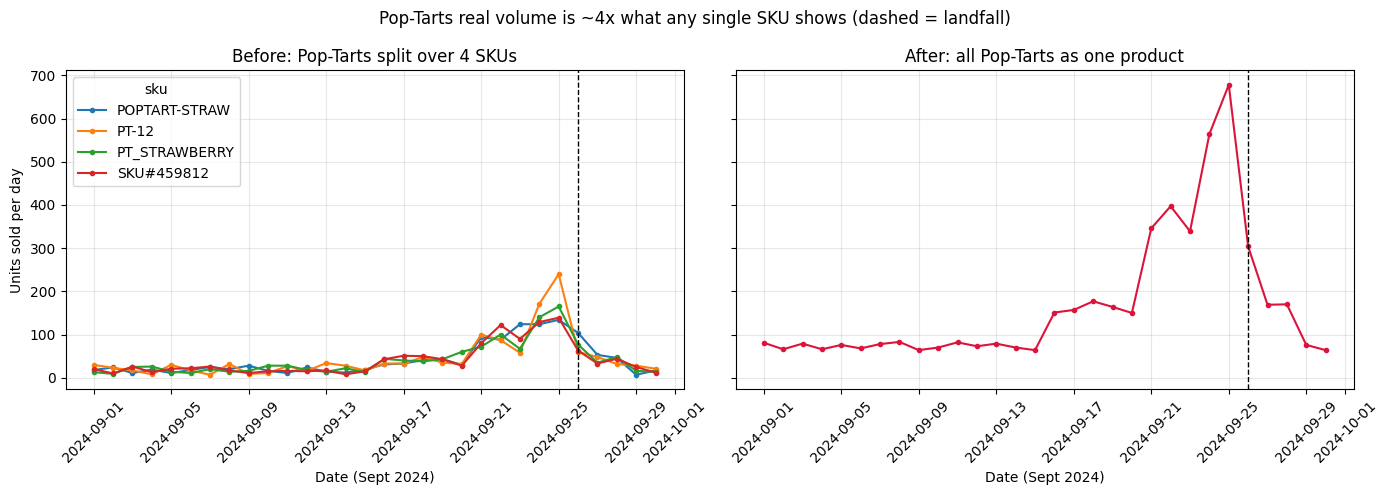

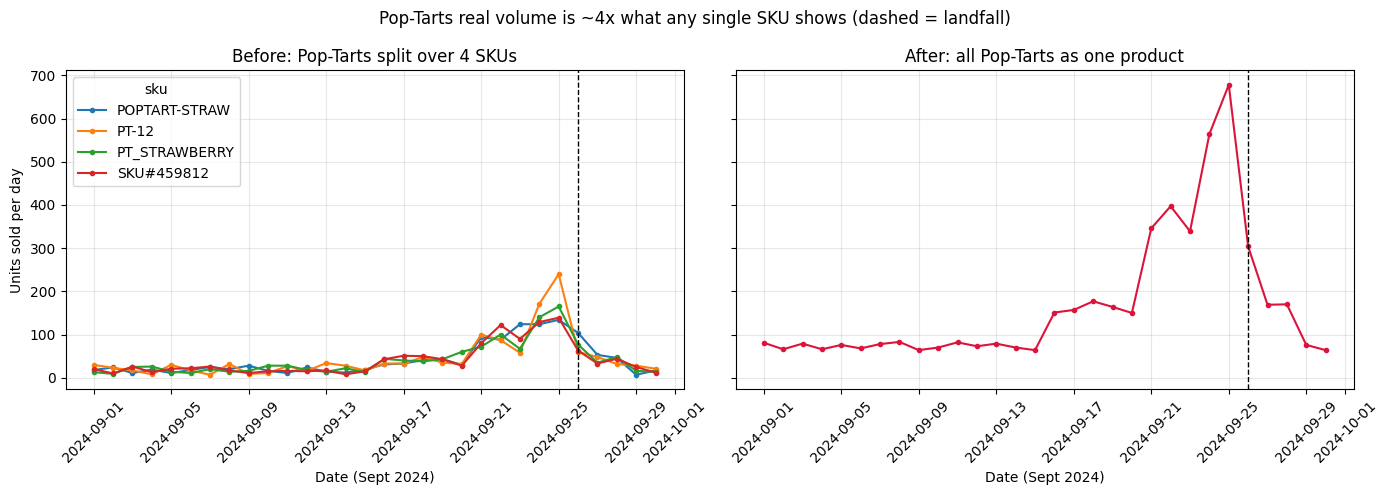

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for c in frag.columns:
    axes[0].plot(frag.index, frag[c], marker="o", markersize=3, label=c)
axes[0].set_title("Before: Pop-Tarts split over 4 SKUs")
axes[0].legend(title="sku")
axes[1].plot(cons.index, cons, marker="o", markersize=3, color="crimson")
axes[1].set_title("After: all Pop-Tarts as one product")
for ax in axes:
    ax.axvline(LANDFALL, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("Date (Sept 2024)")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Units sold per day")
fig.suptitle("Pop-Tarts real volume is ~4x what any single SKU shows (dashed = landfall)")
plt.tight_layout()
plt.show()

**Q2 answer:** 45 sku codes and 63 product_name spellings map to 20 real products. Total units remain the same at 47,897. Pop-Tarts Strawberry is the biggest family with 4 skus. True volume is about 73 units/day in the baseline and 377 units/day in the 7 days before landfall (+414%). Peak is ~680 on Sep 25. In the fragmented view, each SKU shows ~17-20 in the normal case and ~90-100 in the surge case. So while you can see that the % jump in sales is about the same in both views, you can’t see how big the sales really are: ordering- buyer for single sku will order about 1/4 of what stores need and will run out of product during high demand period; priority - poptarts looks like a small product when split up into individual skus, but when combined as a single product, it’s one of the highest moving items; hidden stockouts- If a single sku sells out, the other 3 skus for Pop-Tarts Strawberry will still show sales, thus hiding the fact that the product as a whole is out of stock.

## Q3 — Weather correlation (Hershi)

> How do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

Tip for the lag part: compare daily units to the weather shifted a few days, e.g. `daily["units"].corr(daily["wind"].shift(-2))`.

,Max wind,Precipitation,Pressure
Alcohol,0.41,-0.06,-0.34
Baby,-0.12,-0.26,0.14
Breakfast,0.46,-0.23,-0.39
Electronics,0.25,-0.17,-0.17
Emergency,0.51,-0.24,-0.37
Entertainment,0.41,-0.18,-0.20
Grocery,0.16,-0.30,-0.00
Health,0.36,-0.21,-0.29
Household,0.37,-0.20,-0.24
Snacks,0.07,0.06,0.00


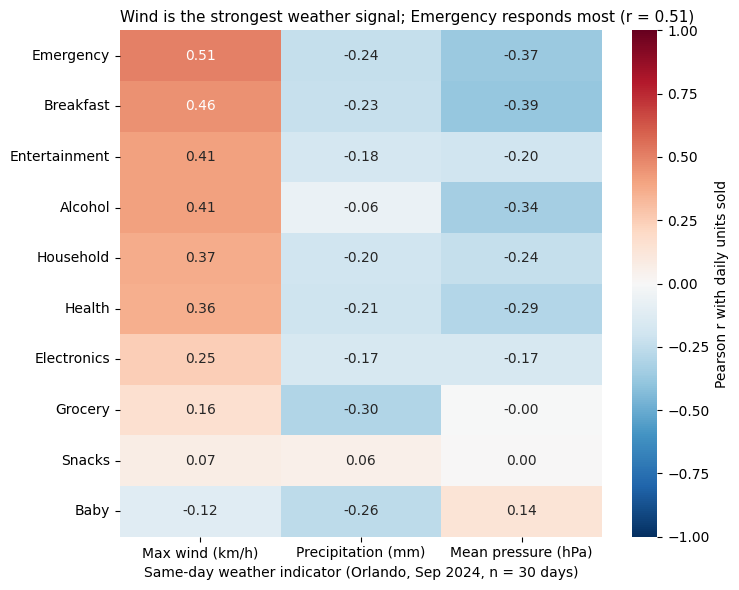

In [29]:
# TODO (Hershi): correlations by category (table or heatmap)
wx_cols = ["windspeed_10m_max", "precipitation_sum", "pressure_mean_hpa"]

cat_daily = (orlando.pivot_table(index="date", columns="category", values="quantity",
                                 aggfunc="sum", fill_value=0))
cat_wx = cat_daily.join(weather.set_index("date")[wx_cols], how="inner")
assert len(cat_wx) == len(cat_daily)

corr_table = pd.DataFrame({w: cat_wx[cat_daily.columns].corrwith(cat_wx[w]) for w in wx_cols})
corr_table.columns = ["Max wind", "Precipitation", "Pressure"]
display(corr_table.round(2))

order = corr_table["Max wind"].sort_values(ascending=False).index
plot_tbl = corr_table.loc[order].copy()
plot_tbl.columns = ["Max wind (km/h)", "Precipitation (mm)", "Mean pressure (hPa)"]
top = order[0]
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(plot_tbl, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "Pearson r with daily units sold"}, ax=ax)
ax.set_title(f"Wind is the strongest weather signal; {top} responds most (r = {corr_table.loc[top,'Max wind']:.2f})",
             loc="left", fontsize=11)
ax.set_xlabel("Same-day weather indicator (Orlando, Sep 2024, n = 30 days)")
ax.set_ylabel("")
plt.tight_layout(); plt.show()


,Max wind,Precipitation,Pressure
lag_days (+ = weather leads sales),,,
-3,0.67,-0.15,-0.52
-2,0.77,-0.24,-0.65
-1,0.69,-0.26,-0.53
0,0.46,-0.26,-0.32
1,0.25,-0.43,-0.23
2,0.15,-0.42,-0.20
3,-0.03,-0.38,-0.10


Each r uses 30 - |k| days, so 27 to 30 observations.


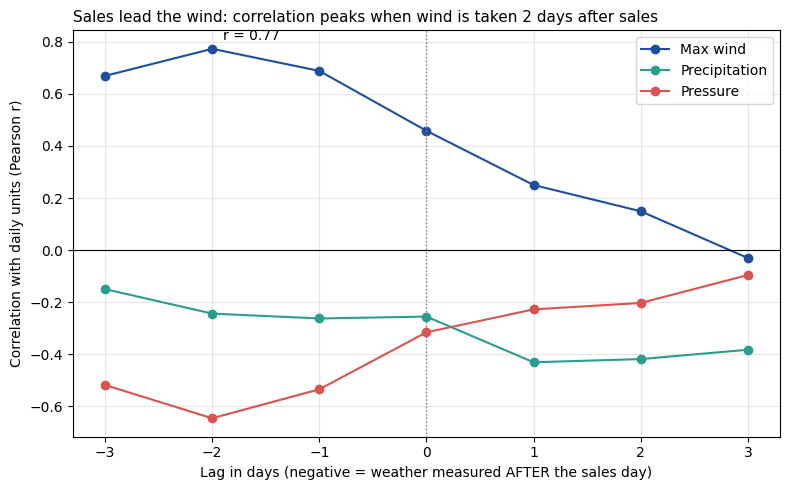

Sales peak: 2024-09-24 | Wind peak: 2024-09-26


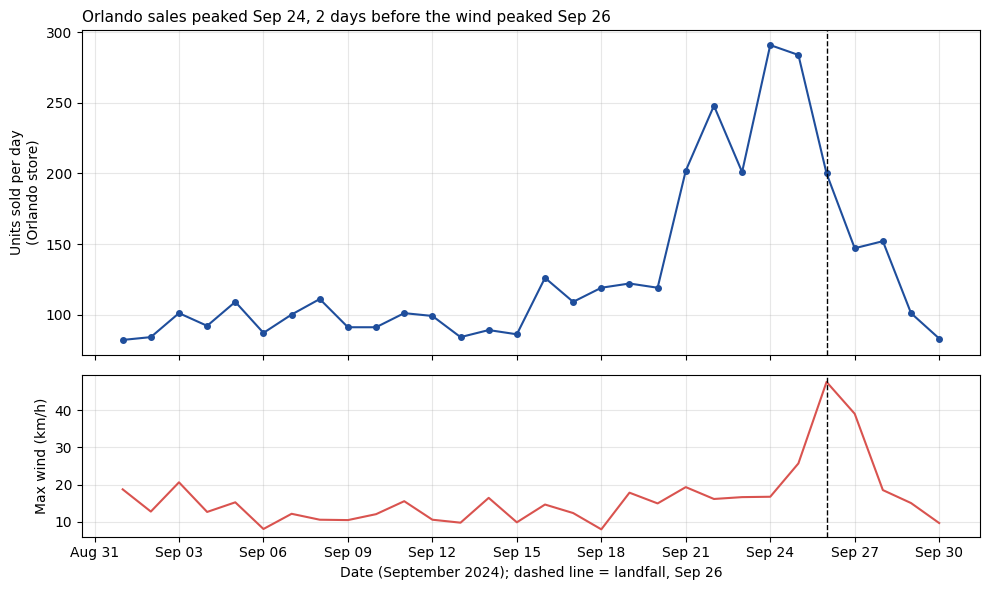

In [32]:
# TODO (Hershi): lag analysis + chart (scatter, heatmap, or sales vs wind over time)
# Convention: shift(k) with k>0 means weather from k days EARLIER than the sales day (weather leads).
# k<0 means weather from later days (sales lead weather).

import matplotlib.dates as mdates
LANDFALL = pd.Timestamp("2024-09-26")   # needed by chart 3 too, in case it's also undefined

lags = range(-3, 4)
lag_tbl = pd.DataFrame({
    "Max wind":      [daily["units"].corr(daily["windspeed_10m_max"].shift(k)) for k in lags],
    "Precipitation": [daily["units"].corr(daily["precipitation_sum"].shift(k)) for k in lags],
    "Pressure":      [daily["units"].corr(daily["pressure_mean_hpa"].shift(k)) for k in lags],
}, index=pd.Index(list(lags), name="lag_days (+ = weather leads sales)"))
display(lag_tbl.round(2))
print("Each r uses 30 - |k| days, so 27 to 30 observations.")

# Chart 2: lag profile as lines
best = lag_tbl["Max wind"].idxmax()
fig, ax = plt.subplots(figsize=(8, 5))
for col, c in zip(lag_tbl.columns, ["#1f4e9c", "#2a9d8f", "#d9534f"]):
    ax.plot(lag_tbl.index, lag_tbl[col], marker="o", color=c, label=col)
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="gray", ls=":", lw=1)
ax.annotate(f"r = {lag_tbl.loc[best,'Max wind']:.2f}", (best, lag_tbl.loc[best, "Max wind"]),
            textcoords="offset points", xytext=(8, 6))
ax.set_xticks(list(lag_tbl.index))
ax.set_xlabel("Lag in days (negative = weather measured AFTER the sales day)")
ax.set_ylabel("Correlation with daily units (Pearson r)")
ax.set_title(f"Sales lead the wind: correlation peaks when wind is taken {abs(best)} days after sales",
             loc="left", fontsize=11)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Chart 3: stacked panels instead of a dual axis
peak_s = daily["units"].idxmax(); peak_w = daily["windspeed_10m_max"].idxmax()
print("Sales peak:", peak_s.date(), "| Wind peak:", peak_w.date())   # confirm before writing markdown
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(daily.index, daily["units"], marker="o", ms=4, color="#1f4e9c")
a2.plot(daily.index, daily["windspeed_10m_max"], color="#d9534f")
for a in (a1, a2):
    a.axvline(LANDFALL, color="black", ls="--", lw=1); a.grid(alpha=0.3)
a1.set_ylabel("Units sold per day\n(Orlando store)")
a2.set_ylabel("Max wind (km/h)")
a2.set_xlabel("Date (September 2024); dashed line = landfall, Sep 26")
a2.xaxis.set_major_locator(mdates.DayLocator(interval=3))
a2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
a1.set_title(f"Orlando sales peaked {peak_s:%b %d}, {(peak_w - peak_s).days} days before the wind peaked {peak_w:%b %d}",
             loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Q3 answer:** Method. We pulled daily precipitation and max wind speed, plus hourly sea-level pressure averaged to daily means, from the Open-Meteo archive API (https://archive-api.open-meteo.com/v1/archive) for the Orlando store (FL-239) for Sep 1–30, 2024. We chose one store so the weather matches a single location. The API was called with timezone=America/New_York, so weather days are local calendar days, and POS timestamps (no timezone marker, assumed local store time) were truncated to dates. Daily sales were joined to weather with validate="one_to_one": 30 rows before and 30 after, all matched. Rows with missing timestamps (75 of Orlando’s 2,103 raw rows) could not be placed on a day and were dropped.

Correlation by category. Wind is the strongest indicator. Same-day correlations with units sold are highest for Emergency (0.51), Breakfast (0.46), Alcohol and Entertainment (0.41), while Baby (-0.12) and Snacks (0.07) show no relationship. Precipitation is weakly negative for almost every category (-0.06 to -0.30). Pressure is negative for most categories (Breakfast -0.39, Emergency -0.37, Alcohol -0.34), consistent with buying rising as pressure fell.

Lag. Purchasing led the weather. Total-unit correlation with wind rises from 0.46 on the same day to 0.77 when sales are compared with wind two days later, and pressure goes from -0.32 to -0.65. Sales peaked on about Sep 24 while wind peaked at landfall on Sep 26. This fits stockpiling in response to forecasts and warnings rather than to conditions at the store. Precipitation correlates most negatively with sales at lags of +1 and +2 days (about -0.42), suggesting a post-storm slump.

Caveats. This is one store, one storm and 27–30 daily observations per correlation. Consecutive days are not independent, so the effective sample is smaller than n, and picking the best of 21 variable-lag combinations flatters the maximum. The result is a timing pattern, not a causal estimate. Forecast information, which we believe drives the behavior, is not in our data.



## Q4 — Store-level geographic patterns (Angelia)

Helene made landfall near Perry, FL (about 30.1 N, 83.6 W). I used a rough distance to that point (degrees x 69 miles). Its not exact but good enough to rank stores closest to farthest.

In [ ]:
# Store file -14 rows but only 12 stores (FL239 and FL_287 are repeats), state is FL / Florida / Fla., and Tallahassee (FL-619) is missing lat/lon so we filled it in by hand from google maps.
stores = stores_raw.copy()
stores["store_id"] = clean_store_id(stores["store_id"])
stores = stores.drop_duplicates(subset="store_id").copy()
stores["state"] = "FL"
stores["region"] = stores["region"].str.strip()
stores.loc[stores["store_id"] == "FL-619", ["latitude", "longitude"]] = ["30.4383", "-84.2807"]
stores["latitude"] = stores["latitude"].astype(float)
stores["longitude"] = stores["longitude"].astype(float)

# every store in the sales data should now match the store file
print("unmatched store ids:", set(tx["store_id"]) - set(stores["store_id"]))
print(len(stores), "stores")

unmatched store ids: set()
12 stores
unmatched store ids: set()
12 stores


In [ ]:
stores["miles_to_landfall"] = (((stores["latitude"] - 30.12) ** 2 +
                                (stores["longitude"] + 83.58) ** 2) ** 0.5 * 69).round(0)

store_daily = tx.groupby(["store_id", "date"])["quantity"].sum().unstack()   # rows = store, cols = day

q4 = pd.DataFrame({
    "baseline_avg": store_daily.loc[:, BASELINE[0]:BASELINE[1]].mean(axis=1),
    "surge_avg": store_daily.loc[:, SURGE[0]:SURGE[1]].mean(axis=1),
})
q4["multiple"] = q4["surge_avg"] / q4["baseline_avg"]

# timing: first day a store sold 2x its own baseline, and its peak day
after = store_daily.loc[:, "2024-09-16":"2024-09-26"]
q4["first_2x_day"] = after.gt(2 * q4["baseline_avg"], axis=0).idxmax(axis=1).dt.strftime("%b %d")
q4["peak_day"] = store_daily.idxmax(axis=1).dt.strftime("%b %d")

q4 = q4.join(stores.set_index("store_id")[["city", "region", "miles_to_landfall"]]).sort_values("miles_to_landfall")

mean_m, std_m = q4["multiple"].mean(), q4["multiple"].std()
q4["outlier"] = (q4["multiple"] - mean_m).abs() > 1.5 * std_m
print(f"avg multiple {mean_m:.2f}, std {std_m:.2f}")
print("corr(distance, multiple):", round(q4["miles_to_landfall"].corr(q4["multiple"]), 2))
q4.round(2)

avg multiple 2.46, std 0.12
corr(distance, multiple): 0.25


,baseline_avg,surge_avg,multiple,first_2x_day,peak_day,city,region,miles_to_landfall,outlier
store_id,,,,,,,,,
FL-619,86.13,224.14,2.60,Sep 21,Sep 24,Tallahassee,Panhandle,53.0,False
FL-078,92.40,219.00,2.37,Sep 22,Sep 25,Gainesville,North,92.0,False
FL-412,89.47,222.86,2.49,Sep 21,Sep 25,Jacksonville,North,134.0,False
FL-105,91.73,231.71,2.53,Sep 21,Sep 25,Tampa,West,169.0,False
FL-445,94.53,232.00,2.45,Sep 21,Sep 24,St. Petersburg,West,175.0,False
FL-302,96.27,239.43,2.49,Sep 21,Sep 25,Lakeland,Central,182.0,False
FL-239,93.80,209.57,2.23,Sep 21,Sep 24,Orlando,Central,187.0,True
FL-156,94.93,229.14,2.41,Sep 21,Sep 24,Daytona Beach,East,187.0,False
FL-287,91.07,220.14,2.42,Sep 21,Sep 25,Kissimmee,Central,196.0,False


avg multiple 2.46, std 0.12
corr(distance, multiple): 0.25


,baseline_avg,surge_avg,multiple,first_2x_day,peak_day,city,region,miles_to_landfall,outlier
store_id,,,,,,,,,
FL-619,86.13,224.14,2.60,Sep 21,Sep 24,Tallahassee,Panhandle,53.0,False
FL-078,92.40,219.00,2.37,Sep 22,Sep 25,Gainesville,North,92.0,False
FL-412,89.47,222.86,2.49,Sep 21,Sep 25,Jacksonville,North,134.0,False
FL-105,91.73,231.71,2.53,Sep 21,Sep 25,Tampa,West,169.0,False
FL-445,94.53,232.00,2.45,Sep 21,Sep 24,St. Petersburg,West,175.0,False
FL-302,96.27,239.43,2.49,Sep 21,Sep 25,Lakeland,Central,182.0,False
FL-239,93.80,209.57,2.23,Sep 21,Sep 24,Orlando,Central,187.0,True
FL-156,94.93,229.14,2.41,Sep 21,Sep 24,Daytona Beach,East,187.0,False
FL-287,91.07,220.14,2.42,Sep 21,Sep 25,Kissimmee,Central,196.0,False


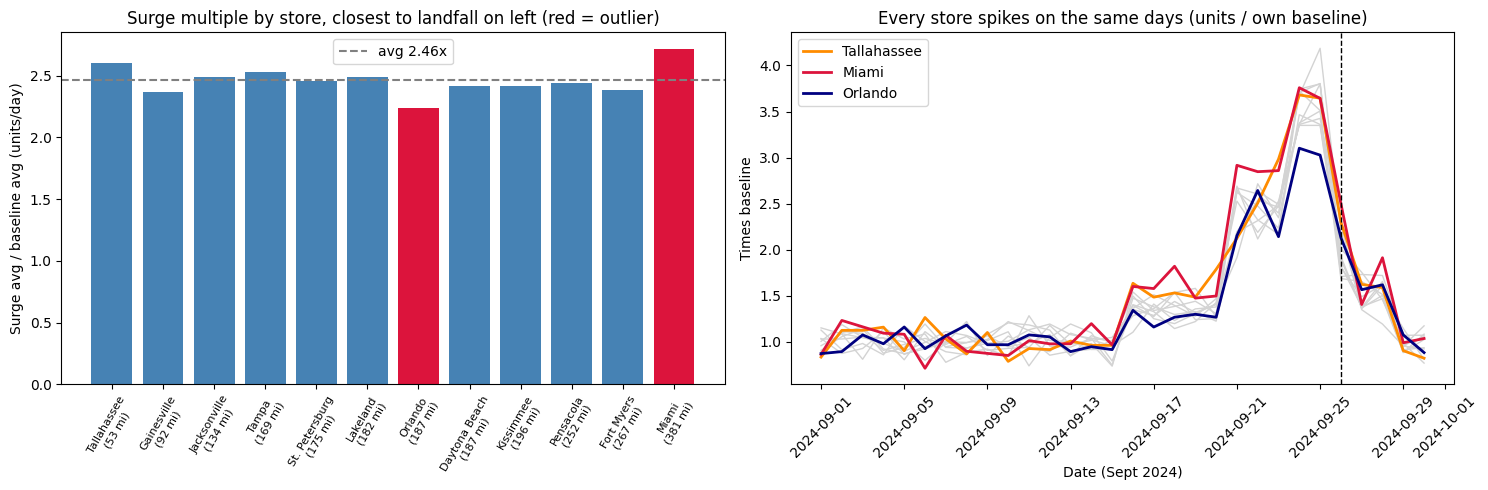

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors = ["crimson" if o else "steelblue" for o in q4["outlier"]]
labels = q4["city"] + "\n(" + q4["miles_to_landfall"].astype(int).astype(str) + " mi)"
axes[0].bar(labels, q4["multiple"], color=colors)
axes[0].axhline(mean_m, color="gray", linestyle="--", label=f"avg {mean_m:.2f}x")
axes[0].set_title("Surge multiple by store, closest to landfall on left (red = outlier)")
axes[0].set_ylabel("Surge avg / baseline avg (units/day)")
axes[0].tick_params(axis="x", rotation=60, labelsize=8)
axes[0].legend()

norm = store_daily.div(q4["baseline_avg"], axis=0)
for sid in norm.index:
    axes[1].plot(norm.columns, norm.loc[sid], color="lightgray", linewidth=1)
for sid, col in [("FL-619", "darkorange"), ("FL-330", "crimson"), ("FL-239", "navy")]:
    axes[1].plot(norm.columns, norm.loc[sid], color=col, linewidth=2, label=q4.loc[sid, "city"])
axes[1].axvline(LANDFALL, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Every store spikes on the same days (units / own baseline)")
axes[1].set_ylabel("Times baseline")
axes[1].set_xlabel("Date (Sept 2024)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

**Q4 answer:** No, the surge of stores closer to the hurricane path did not occur earlier or was greater. All 12 stores hit 2x their own baseline on Sep 21 (Gainesville one day later) and every store peaked on Sep 24 or 25. The multiples for surge were fairly tight, 2.2x to 2.7x (avg 2.46x). The correlation of distance vs multiple was +0.25, so if anything the more distant stores increased slightly more than the average, the opposite of what we would have expected. Tallahassee, the closest store (~53 mi) was 2.60x, only slightly above the average.

Outliers(>1.5 std from the average):
- Miami (FL-330), 2.71x: The highest multiple even though it is the farthest store (~381 mi). It appears Miami shoppers react to any storm warning, and the early forecasts were very uncertain as to where Helene would go.
- Orlando (FL-239), 2.23x: The lowest multiple for stores in Florida. This store is inland, so perhaps people did not feel as threatened.

Therefore, plan the surge statewide and move stock ~5-7 days before landfall to every store, not just stores on the predicted path (caveats: one storm, a rough straight-line distance, and Tallahassee’s coordinates were filled in by hand).

## Q5 — Signal vs. artifact: board games (Angelia)




In [ ]:
# The claim is board games/entertainment went up +250%. I checked it 3 ways: the SQLite database, the cleaned transactions, and an audit of whats actually in the category.
# step 1 -databse
# the db has messy dates too: some 2024-09-01, some 20240901
print("dates without a dash:", (~dss["date"].str.contains("-")).sum())
dss["date"] = pd.to_datetime(dss["date"], format="mixed")
inv["date"] = pd.to_datetime(inv["date"], format="mixed")
print("total_units that arent whole numbers:", (dss["total_units"] % 1 != 0).sum())

db_cat = dss.groupby(["date", "category"])["total_units"].sum().unstack()
db_surge = ((db_cat.loc[SURGE[0]:SURGE[1]].mean() /
             db_cat.loc[BASELINE[0]:BASELINE[1]].mean() - 1) * 100).sort_values()
print(db_surge.round(0))

ent_base = db_cat.loc[BASELINE[0]:BASELINE[1], "Entertainment"].mean()
print("\nentertainment peak day (Sep 24) vs baseline: +{:.0f}%".format(
      (db_cat.loc["2024-09-24", "Entertainment"] / ent_base - 1) * 100))

dates without a dash: 218
total_units that arent whole numbers: 76
category
Snacks            18.0
Baby              54.0
Grocery           62.0
Electronics       97.0
Household        104.0
Alcohol          112.0
Health           119.0
Entertainment    145.0
Emergency        183.0
Breakfast        236.0
dtype: float64

entertainment peak day (Sep 24) vs baseline: +272%


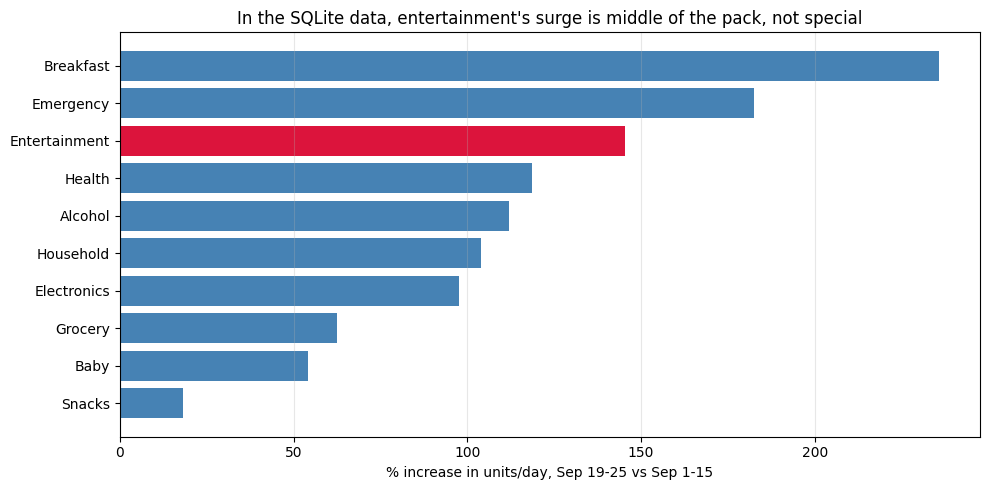

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["crimson" if c == "Entertainment" else "steelblue" for c in db_surge.index]
ax.barh(db_surge.index, db_surge.values, color=colors)
ax.set_xlabel("% increase in units/day, Sep 19-25 vs Sep 1-15")
ax.set_title("In the SQLite data, entertainment's surge is middle of the pack, not special")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Step 2 — cross check with transactions

If people really wanted games for the storm, Monopoly's **share** of all units should go up. If its just more people in the store, the share stays flat.

In [ ]:
# The claim is board games/entertainment went up +250% so I checked it 3 ways: the SQLite database, the cleaned transactions, and an audit of whats actually in the category.
# step 1 -databse
# the db has messy dates too: some 2024-09-01, some 20240901
print("whats inside entertainment:")
print(tx[tx["category"] == "Entertainment"].groupby("canonical_product")["sku"].unique())

def pct_surge(df):
    d = df.groupby("date")["quantity"].sum()
    return (d.loc[SURGE[0]:SURGE[1]].mean() / d.loc[BASELINE[0]:BASELINE[1]].mean() - 1) * 100

compare = pd.Series({
    "Monopoly (3 skus)": pct_surge(tx[tx["canonical_product"] == "Monopoly Board Game"]),
    "Playing Cards": pct_surge(tx[tx["canonical_product"] == "Playing Cards"]),
    "Pop-Tarts": pct_surge(tx[tx["canonical_product"] == "Pop-Tarts Strawberry"]),
    "Bottled Water": pct_surge(tx[tx["canonical_product"] == "Bottled Water 24-Pack"]),
    "ALL products": pct_surge(tx),
})
print(compare.round(0))

all_daily = tx.groupby("date")["quantity"].sum()
mono_daily = tx[tx["canonical_product"] == "Monopoly Board Game"].groupby("date")["quantity"].sum()
mono_share = mono_daily / all_daily * 100
print("\nMonopoly share of units - baseline {:.1f}%, surge {:.1f}%".format(
      mono_share.loc[BASELINE[0]:BASELINE[1]].mean(), mono_share.loc[SURGE[0]:SURGE[1]].mean()))


whats inside entertainment:
canonical_product
Monopoly Board Game    [BG-MONO, MONOPOLY-01, GAME-MONO]
Playing Cards                   [CARDS-01, PLAYCARD-STD]
Name: sku, dtype: object
Monopoly (3 skus)    160.0
Playing Cards         99.0
Pop-Tarts            414.0
Bottled Water        197.0
ALL products         146.0
dtype: float64

Monopoly share of units - baseline 3.9%, surge 4.0%


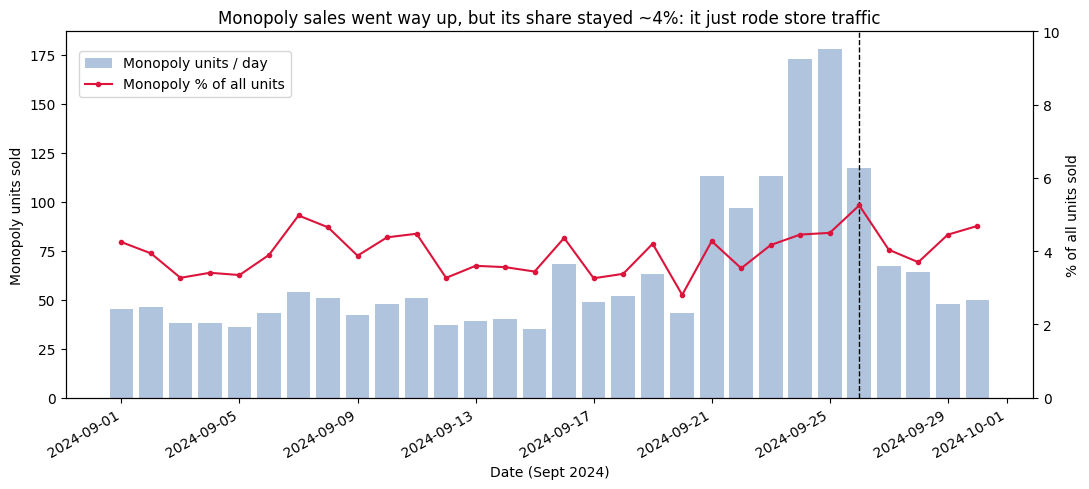

In [ ]:
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(mono_daily.index, mono_daily, color="lightsteelblue", label="Monopoly units / day")
ax1.set_ylabel("Monopoly units sold")
ax1.set_xlabel("Date (Sept 2024)")
ax2 = ax1.twinx()
ax2.plot(mono_share.index, mono_share, color="crimson", marker="o", markersize=3, label="Monopoly % of all units")
ax2.set_ylabel("% of all units sold")
ax2.set_ylim(0, 10)
ax1.axvline(LANDFALL, color="black", linestyle="--", linewidth=1)
ax1.set_title("Monopoly sales went way up, but its share stayed ~4%: it just rode store traffic")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

             sku           product_name       category package_size unit_cost
14       BG-MONO    Monopoly Board Game  ENTERTAINMENT          1pk      9.96
15   MONOPOLY-01    Monopoly Board Game  entertainment      24-pack     12.51
16     GAME-MONO  Board Game - Monopoly  ENTERTAINMENT          1pk       NaN
17      CARDS-01          Playing Cards  ENTERTAINMENT          4pk      2.45
18  PLAYCARD-STD          PLAYING CARDS  entertainment      24-pack      2.39

inventory skus that never show up in sales: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']
missing units_on_order: 626


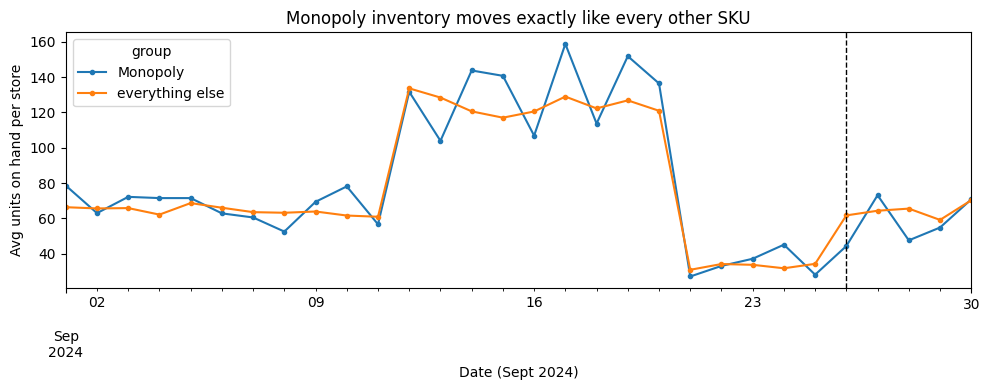

In [ ]:
# Step 3 — catalog and inventory audit
game_skus = ["BG-MONO", "MONOPOLY-01", "GAME-MONO", "CARDS-01", "PLAYCARD-STD"]
print(catalog[catalog["sku"].isin(game_skus)][["sku", "product_name", "category", "package_size", "unit_cost"]])

print("\ninventory skus that never show up in sales:", sorted(set(inv["sku"]) - set(tx["sku"])))
print("missing units_on_order:", inv["units_on_order"].isna().sum())

inv["group"] = "everything else"
inv.loc[inv["sku"].isin(["BG-MONO", "MONOPOLY-01", "GAME-MONO"]), "group"] = "Monopoly"
inv_trend = inv.groupby(["date", "group"])["units_on_hand"].mean().unstack()

ax = inv_trend.plot(figsize=(10, 4), marker="o", markersize=3)
ax.axvline(LANDFALL, color="black", linestyle="--", linewidth=1)
ax.set_title("Monopoly inventory moves exactly like every other SKU")
ax.set_ylabel("Avg units on hand per store")
ax.set_xlabel("Date (Sept 2024)")
plt.tight_layout()
plt.show()

**Q5 answer**: mostly an artifact(not a special demand signal)

1. We couldn't reproduce +250% with a fair window - inn the SQLite `daily_sales_summary`, entertainment went up +145% (Sep 19-25 vs Sep 1-15). You only get something like +250% by cherry picking the peak day (Sep 24 was +272%).
2.*Everything went up that much. All products combined went up +146% in the transactions, basically the same as entertainment. Monopoly was +160% and playing cards +99%. Compare that to Pop-Tarts (+414%) and water (+197%), which really did beat store traffic.
3. Monopoly's share didn't change, where Monopoly units went up from 3.9% of units in the baseline to 4.0% in the surge. If people were buying games because of the storm, then Monopoly’s share would have gone up. But instead, more games sold because more people were in the store.
4. The category is messy (lumping + miscoding). The category of Entertainment is 2 products (Monopoly and cards) with 5 different skus and 4 different labels. The catalog says MONOPOLY-01 is a 24-pack but BG-MONO is a 1pk. GAME-MONO has no unit cost. So you have a messy category with a peak-day number and you can get a scary headline.
5. Inventory shows nothing special, where monopoly units on hand rise and fall exactly like every other sku (even junk skus like UNKNOWN-99 that never sell). units_on_order stays flat at ~50 all month, so there's no sign of a game-specific restock or reporting lag. The db also has its own problems (218 dates in a different format, 76 fractional unit counts, 626 missing units_on_order).

My recommendation is to not stock up on extra board games for the next storm. They will sell at about the same percentage of total units that they normally do (~4%). Buying more "survival itmes" would be a better way to spend money in this cirumstance (e.g. Pop-Tarts, water, emergency supplies). Also, merge the Monopoly skus and correct the catalog sizes for them before the next storm.